In [5]:
import pandas as pd
import matplotlib.pyplot as plt


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("C:/Users/ASUS/Downloads/hotel_bookings.csv/hotel_bookings.csv")
print("First 5 rows:")
print(df.head())

First 5 rows:
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Dep

In [8]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(119390, 32)


In [9]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')


In [10]:
print("\nData Types:")
print(df.dtypes)


Data Types:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                

In [11]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340

In [12]:
df['children'] = df['children'].fillna(df['children'].median())
df['agent'] = df['agent'].fillna(df['agent'].median())
df['company'] = df['company'].fillna(df['company'].median())

df['country'] = df['country'].fillna(df['country'].mode()[0])

print("Missing values after preprocessing:")
print(df.isnull().sum())

Missing values after preprocessing:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type               

In [13]:
df_encoded = pd.get_dummies(
    df,
    columns=['hotel', 'meal', 'market_segment', 'distribution_channel'],
    drop_first=True
)
print("Shape after encoding:")
print(df_encoded.shape)

print("\nFirst 5 rows:")
print(df_encoded.head())

Shape after encoding:
(119390, 44)

First 5 rows:
   is_canceled  lead_time  arrival_date_year arrival_date_month  \
0            0        342               2015               July   
1            0        737               2015               July   
2            0          7               2015               July   
3            0         13               2015               July   
4            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  children  ...  \
0                        0                     0       2       0.0  ...   
1                        0                     0

In [14]:
numeric_columns = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'adr'
]

print("Selected Numerical Columns:")
print(df[numeric_columns].describe())

Selected Numerical Columns:
           lead_time  stays_in_weekend_nights  stays_in_week_nights  \
count  119390.000000            119390.000000         119390.000000   
mean      104.011416                 0.927599              2.500302   
std       106.863097                 0.998613              1.908286   
min         0.000000                 0.000000              0.000000   
25%        18.000000                 0.000000              1.000000   
50%        69.000000                 1.000000              2.000000   
75%       160.000000                 2.000000              3.000000   
max       737.000000                19.000000             50.000000   

              adults       children            adr  
count  119390.000000  119390.000000  119390.000000  
mean        1.856403       0.103886     101.831122  
std         0.579261       0.398555      50.535790  
min         0.000000       0.000000      -6.380000  
25%         2.000000       0.000000      69.290000  
50%         2.

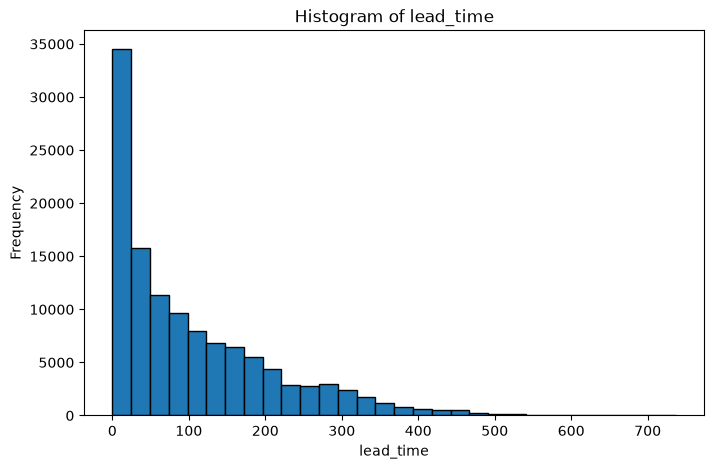

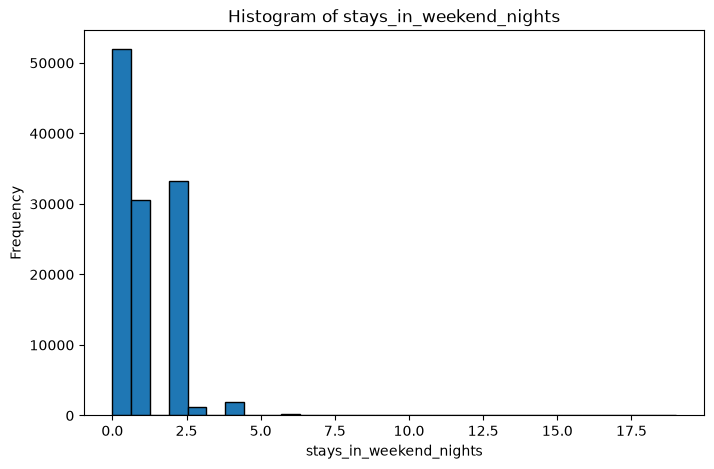

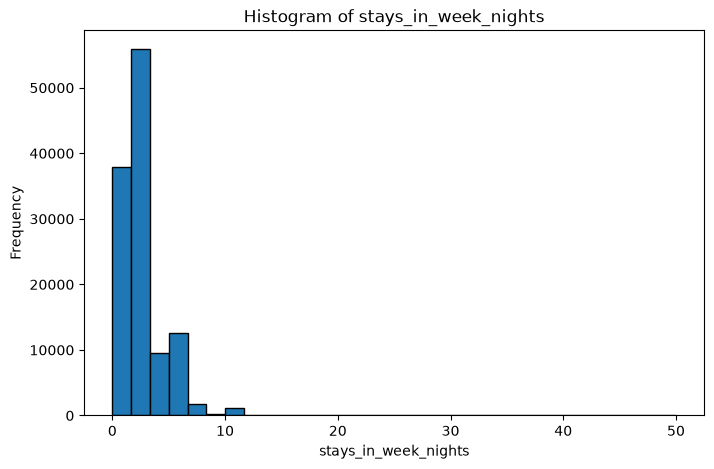

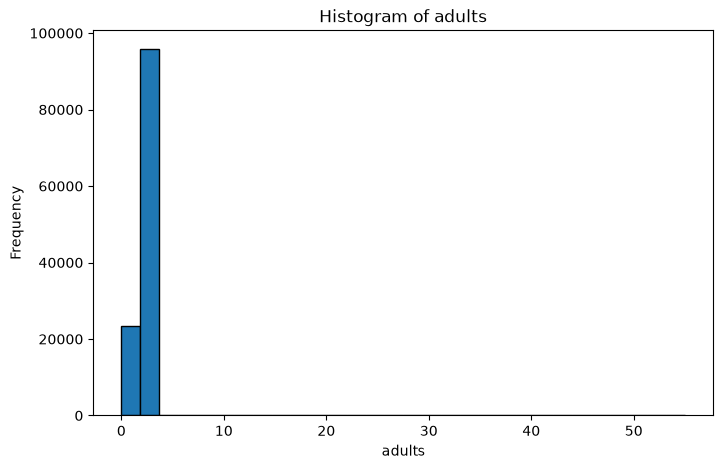

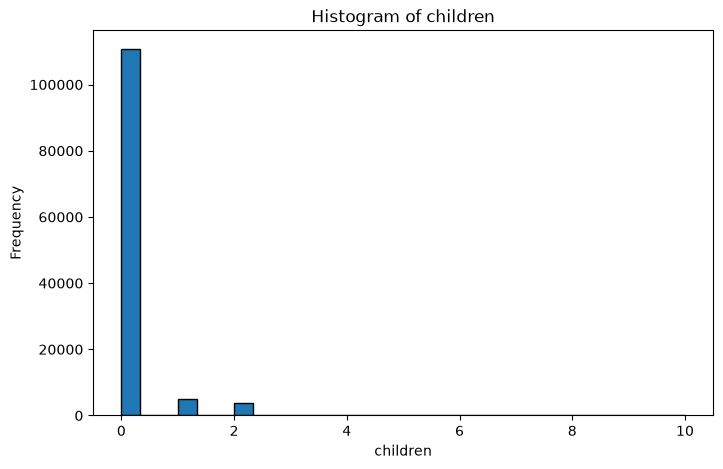

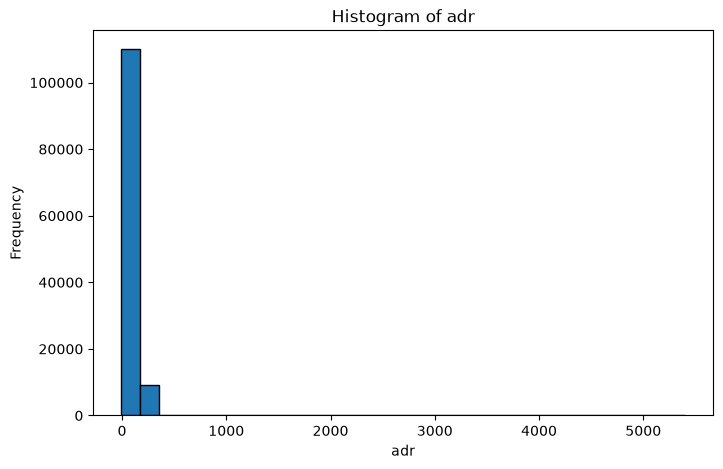

In [15]:
for column in numeric_columns:
    plt.figure(figsize=(8, 5))
    
    plt.hist(df[column], bins=30, edgecolor='black')
    
    plt.title("Histogram of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.show()

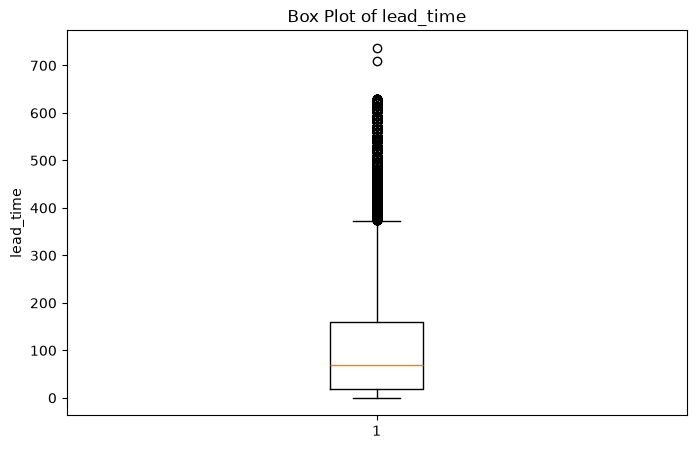

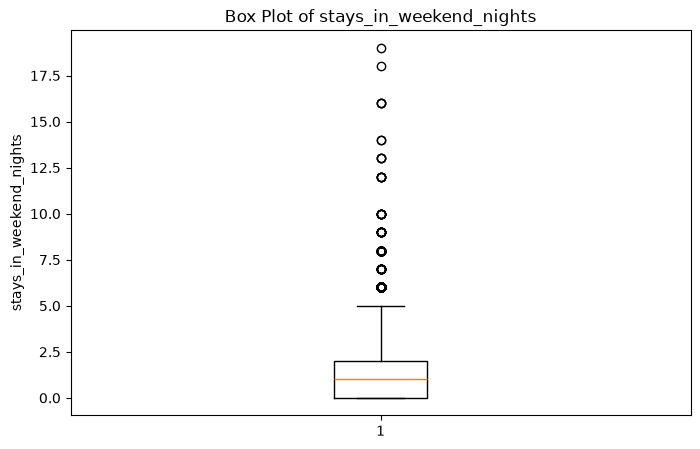

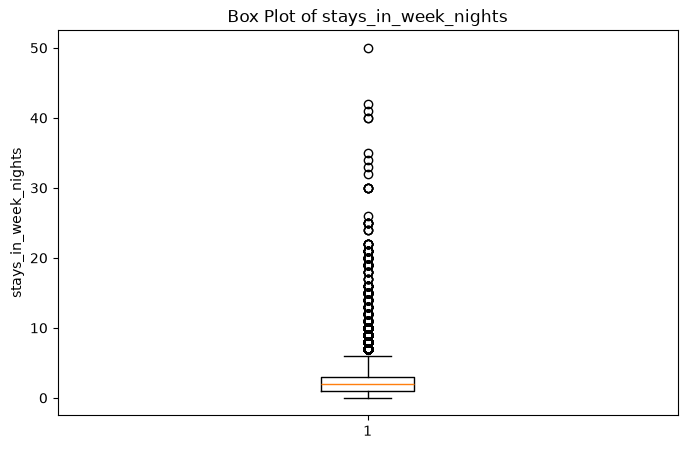

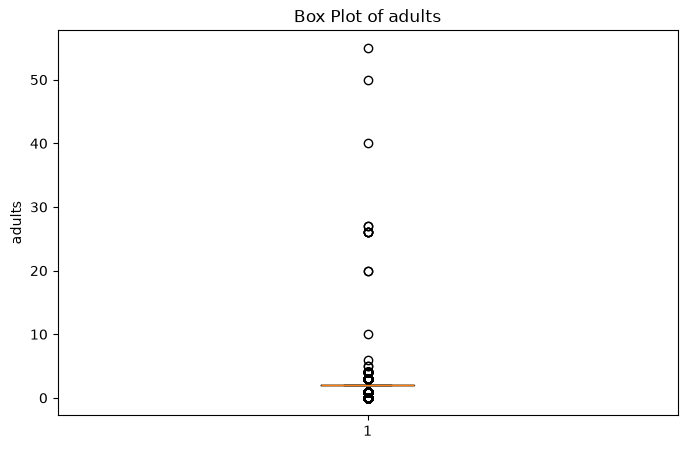

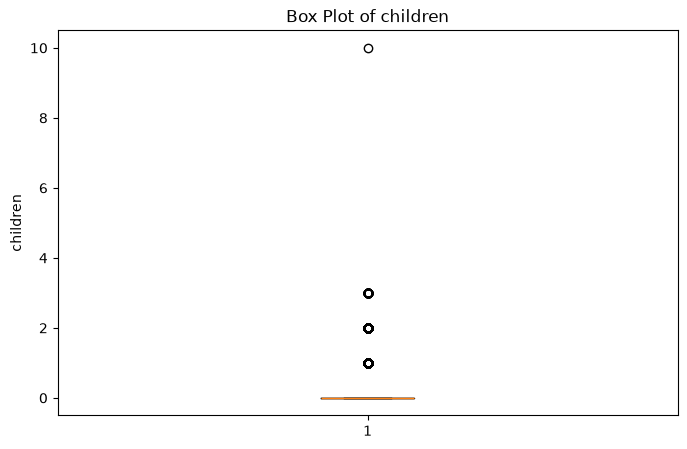

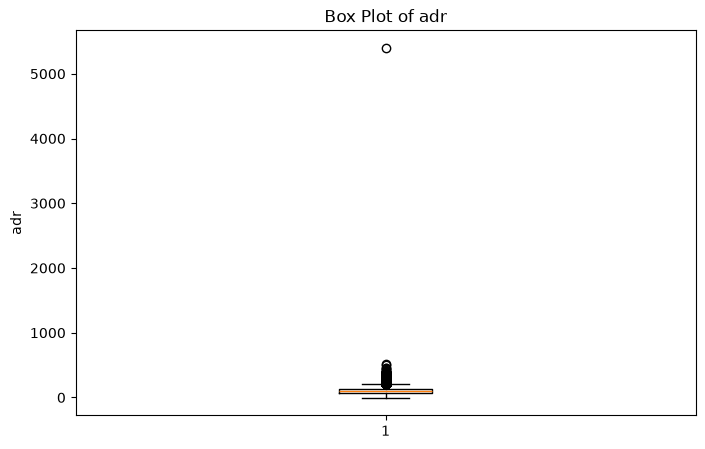

In [16]:

for column in numeric_columns:
    plt.figure(figsize=(8, 5))
    
    plt.boxplot(df[column])
    
    plt.title("Box Plot of " + column)
    plt.ylabel(column)
    
    plt.show()

In [17]:
for column in numeric_columns:
    skewness = df[column].skew()
    kurtosis = df[column].kurt()
    
    print("\nColumn:", column)
    print("Skewness:", round(skewness, 3))
    print("Kurtosis:", round(kurtosis, 3))


Column: lead_time
Skewness: 1.347
Kurtosis: 1.696

Column: stays_in_weekend_nights
Skewness: 1.38
Kurtosis: 7.174

Column: stays_in_week_nights
Skewness: 2.862
Kurtosis: 24.285

Column: adults
Skewness: 18.318
Kurtosis: 1352.115

Column: children
Skewness: 4.113
Kurtosis: 18.674

Column: adr
Skewness: 10.53
Kurtosis: 1013.19


In [18]:
summary = pd.DataFrame({
    'Mean': df[numeric_columns].mean(),
    'Median': df[numeric_columns].median(),
    'Skewness': df[numeric_columns].skew(),
    'Kurtosis': df[numeric_columns].kurt()
})

print(summary.round(3))

                            Mean  Median  Skewness  Kurtosis
lead_time                104.011  69.000     1.347     1.696
stays_in_weekend_nights    0.928   1.000     1.380     7.174
stays_in_week_nights       2.500   2.000     2.862    24.285
adults                     1.856   2.000    18.318  1352.115
children                   0.104   0.000     4.113    18.674
adr                      101.831  94.575    10.530  1013.190
